# Préparation des données

In [22]:
%pip install tensorflow

  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.1-cp314-cp314-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.84.0-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached h5py-3.15.1-cp314-cp314-win_amd64.whl.metadata (3.1 kB)
  Using ca


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import os
import cv2
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np
import tensorflow as tf

In [3]:
def images_to_list(path:str, images:list, labels:list, extensions:tuple):
    try:
        content_list = os.listdir(path)
        for f in content_list:
            if os.path.isdir(os.path.join(path, f)):
                # return kathbas l fonction
                images_to_list(os.path.join(path, f), images, labels, extensions)
            elif f.endswith(extensions):
                images.append(cv2.imread(os.path.join(path, f)))
                labels.append(path.split(os.sep)[-1])
    except FileNotFoundError:
        print(f"{path} :fichier introuvable.")
    except NotADirectoryError:
        print(f"{path} :n'est pas un répertoire.")
    except PermissionError:
        print(f"Besoin de permissions pour le répertoire :{path}.")
    except Exception as e:
        print(f"erreur:\n{e}")

In [4]:
data_dir = os.path.join("..","data","inputs")
images = []
labels = []

images_to_list(path=data_dir, images=images, labels=labels, extensions=("jpeg", "jpg", "bmp", "png"))
display(len(images), len(labels))

7023

7023

<Axes: xlabel='labels', ylabel='count'>

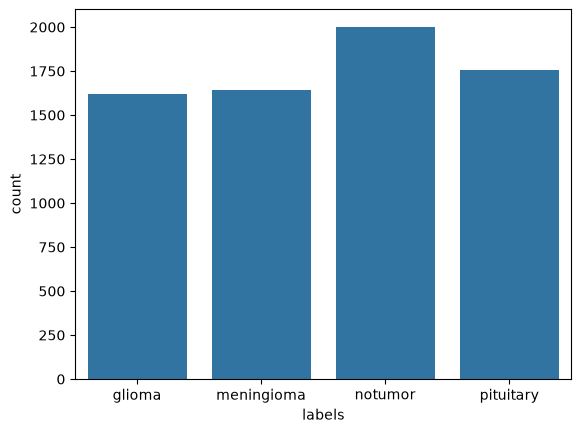

In [5]:
sn.countplot(
    pd.DataFrame(labels, columns=["labels"]),
    x="labels",
)

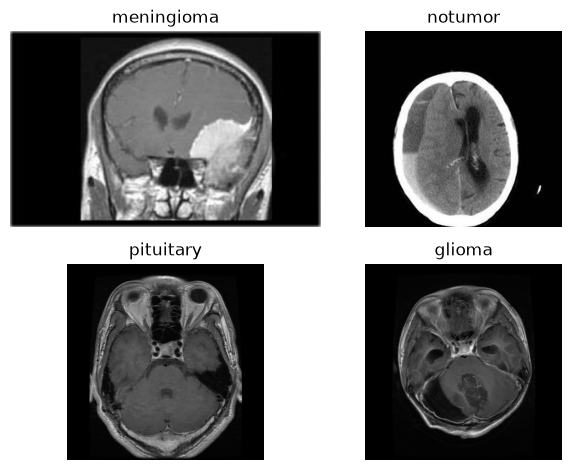

In [6]:
for i, label in enumerate(set(labels)):
    index = labels.index(label)
    ax = plt.subplot(2, 2, i+1)
    plt.imshow(images[index])
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(
    images,
    labels,
    train_size=0.7,
    random_state=1,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=1,
)

display(f"Train set :{len(X_train)} images")
display(f"Validation set :{len(X_val)} images")
display(f"Test set :{len(X_test)} images")

'Train set :4916 images'

'Validation set :1053 images'

'Test set :1054 images'

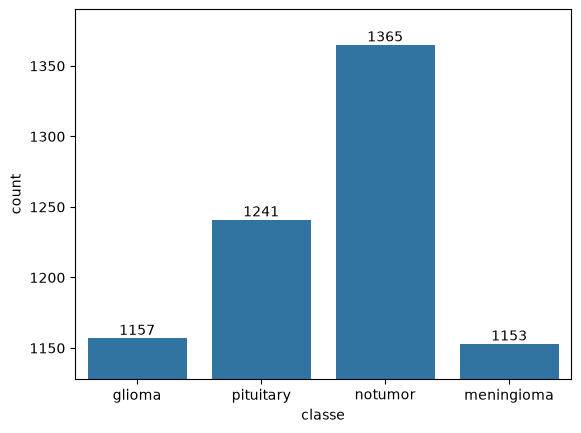

In [ ]:
# train_labels, counts = np.unique(y_train, return_counts=True)
ax = sn.countplot(
    pd.DataFrame(y_train, columns=["classe"]),
    x="classe"
)
ax.bar_label(ax.containers[0], fontsize=10)
# plt.ylim(np.min(counts)-25, np.max(counts)+25)
plt.show()

In [ ]:
train_labels, counts = np.unique(y_train, return_counts=True)

In [ ]:
class_dominateur = np.argmax(counts)
for index, (label, count) in enumerate(zip(train_labels, counts)):
    if index != class_dominateur:
        images_correspond = [
            image 
            for (image,y_label) in zip(X_train, y_train) 
            if y_label==label
        ]
        n_images_in_classe = len(images_correspond)
        n_images_to_add = counts[class_dominateur]-count
        if n_images_in_classe >= n_images_to_add:
            for i in range(n_images_to_add):
                combinaisons_num = np.random.randint(1, 5)

                match combinaisons_num:
                    case 1:
                        images_correspond[i] = cv2.GaussianBlur(
                            src=images_correspond[i], 
                            ksize=(5, 5), 
                            sigmaX=0
                        )
                    case 2:
                        images_correspond[i] = cv2.flip(
                            src=images_correspond[i], 
                            flipCode=1
                        )
                    case 3:
                        noise = np.random.normal(
                            loc=0,
                            scale=10,
                            size=images_correspond[i].shape
                        ).astype(np.float32)
                        noisy_image = images_correspond[i] + noise
                        images_correspond[i] = np.clip(noisy_image, 0, 255).astype(np.uint8)
                    case 4:
                        images_correspond[i] = cv2.GaussianBlur(
                            src=images_correspond[i], 
                            ksize=(5, 5), 
                            sigmaX=0
                        )
                        images_correspond[i] = cv2.flip(
                            src=images_correspond[i], 
                            flipCode=1
                        )
                    case 5:
                        images_correspond[i] = cv2.flip(
                            src=images_correspond[i], 
                            flipCode=1
                        )
                        noise = np.random.normal(
                            loc=0,
                            scale=10,
                            size=images_correspond[i].shape
                        ).astype(np.float32)
                        noisy_image = images_correspond[i] + noise
                        images_correspond[i] = np.clip(noisy_image, 0, 255).astype(np.uint8)
                    case _:
                        print(f"erreur pour l'image {i} de la classe {label}")
            X_train.extend(images_correspond[:n_images_to_add])
            y_train.extend([label]*n_images_to_add)

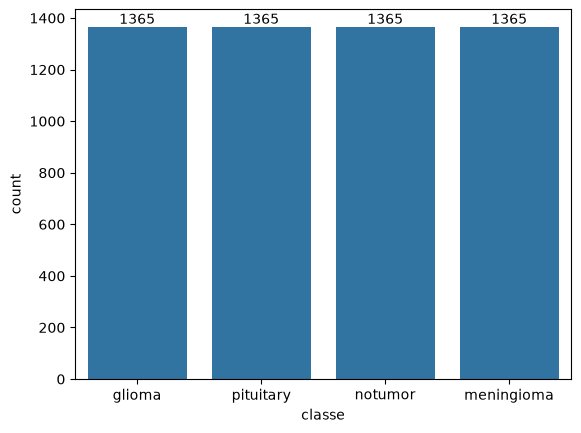

In [21]:
ax = sn.countplot(
    pd.DataFrame(y_train, columns=["classe"]),
    x="classe"
)
ax.bar_label(ax.containers[0], fontsize=10)
plt.show()

In [32]:
# Redimmensionnement d'images avec keras
image_size = (299, 299)
resizer = tf.keras.layers.Resizing(
    image_size[0],
    image_size[1],
    pad_to_aspect_ratio=True,
    fill_value=0,
    data_format="channels_last"
)

resized_X_train = []
for image in X_train:
    resized_X_train.append(resizer(image))

np.array(resized_X_train).shape

(5460, 299, 299, 3)

In [33]:
# Normalisation des images avec keras
rescaler = tf.keras.layers.Rescaling(scale=1./127.5, offset=-1)
preprocessed_X_train = rescaler(resized_X_train)
preprocessed_X_train.shape

TensorShape([5460, 299, 299, 3])

In [35]:
batch_size = 64

train_dataset = tf.data.Dataset.from_tensor_slices(
    (preprocessed_X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(len(X_train), seed=42)
    # .repeat()
    .batch(batch_size)
)

The **shuffle** method uses a fixed-size buffer to shuffle the items as they pass through. Setting a **buffer_size** greater than the number of examples in the Dataset ensures that the data is completely shuffled. The **repeat** method has the Dataset restart when it reaches the end. To limit the number of epochss, set the count argument. The batch method collects a number of examples and stacks them, to create batches. This adds a dimension to their shape. The new dimension is added as the first dimension.

In [36]:
for images, labels in train_dataset.take(1):
    print("Images :", images.shape)
    print("Labels :", labels.shape)

Images : (64, 299, 299, 3)
Labels : (64,)
